In [2]:
# Uncomment the next line to install dependencies if needed.
!pip install numpy matplotlib 'astropy>=5.3' 'astroquery>=0.4.11' fsspec s3fs firefly_client

In [3]:
import io
import json
import warnings

import numpy as np
import matplotlib.pyplot as plt

from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.nddata import Cutout2D
from astropy.table import QTable
from astropy import units as u
from astropy.utils.data import conf
from astropy.visualization import ImageNormalize, PercentileInterval, AsinhStretch, LogStretch, quantity_support
from astropy.wcs import WCS

from firefly_client import FireflyClient
from astroquery.ipac.irsa import Irsa

# Suppress warnings about deprecated units in the spectrum files
warnings.filterwarnings('ignore', message="The unit 'Angstrom' has been deprecated", category=u.UnitsWarning)
warnings.filterwarnings('ignore', message="The unit 'erg' has been deprecated", category=u.UnitsWarning)

# Let matplotlib pick up the axis units from the quantities we plot
quantity_support()

# The Euclid spectrum files can take a while to read,
# which can exceed astropy's default timeout limit. Increase it.
conf.remote_timeout = 120

In [4]:
Irsa.list_catalogs(filter='euclid_dr1', include_metadata_tables=True)

{'euclid_dr1_mer_catalogue_wide_survey': 'Euclid DR1 MER Catalog - Wide Survey',
 'euclid_dr1_mer_catalogue_deep_survey': 'Euclid DR1 MER Catalog - Deep Survey',
 'euclid_dr1_mer_catalogue_wide_mode': 'Euclid DR1 MER Catalog - Wide Mode',
 'euclid_dr1_mer_catalogue_deep_mode': 'Euclid DR1 MER Catalog - Deep Mode',
 'euclid_dr1_mer_catalogue_deep_survey_photometry': 'Euclid DR1 MER Deep Survey Photometry Catalog',
 'euclid_dr1_mer_catalogue_deep_mode_photometry': 'Euclid DR1 MER Deep Mode Photometry Catalog',
 'euclid_dr1_phz_classification_wide': 'Euclid DR1 PHZ Classification Catalog - Wide',
 'euclid_dr1_phz_classification_deep_survey': 'Euclid DR1 PHZ Classification Catalog - Deep Survey',
 'euclid_dr1_phz_photo_z_wide': 'Euclid DR1 PHZ Photo-z Catalog - Wide',
 'euclid_dr1_phz_photo_z_deep_survey': 'Euclid DR1 PHZ Photo-z Catalog - Deep Survey',
 'euclid_dr1_spectro_line_features_spe_line_features_wide_survey': 'Euclid DR1 SPE Lines Catalog - Spectral Line Features - Wide Survey',


In [5]:
table_mer = 'euclid_dr1_mer_catalogue_deep_survey'
table_phz = 'euclid_dr1_phz_photo_z_deep_survey'
table_spe = 'euclid_dr1_spectro_z_spe_galaxy_candidates_deep'

In [6]:
columns_info = Irsa.list_columns(catalog=table_phz)
print(f'{len(columns_info)} columns')

48 columns


In [7]:
# Full list of columns and their description
columns_info

{'object_id': 'Identifier assigned to a detected source by the Euclid MER processing pipeline. The identifier is not guaranteed to be unique.',
 'phz_median': 'The median of the PHZ PDF',
 'phz_70_int_1': 'The smallest PHZ PDF interval containing 70% of the probability - lower value',
 'phz_70_int_2': 'The smallest PHZ PDF interval containing 70% of the probability - upper value',
 'phz_90_int_1': 'The smallest PHZ PDF interval containing 90% of the probability - lower value',
 'phz_90_int_2': 'The smallest PHZ PDF interval containing 90% of the probability - upper value',
 'phz_95_int_1': 'The smallest PHZ PDF interval containing 95% of the probability - lower value',
 'phz_95_int_2': 'The smallest PHZ PDF interval containing 95% of the probability - upper value',
 'phz_mode_1': 'The first mode of the PHZ PDF',
 'phz_mode_1_area': 'The total area of the first mode',
 'phz_mode_2': 'The second mode of the PHZ PDF',
 'phz_mode_2_area': 'The total area of the second mode',
 'bias_id': 'T

In [8]:
######################## User defined section ############################
# Set the center and size of the region to select galaxies from (and of the image cutout below)
ra_cutout = 269.46
dec_cutout = 66.0
im_cutout = 5 * u.arcmin

# Redshift range
z_min, z_max = 0.85, 1.85
##########################################################################

coords_cutout = SkyCoord(ra_cutout, dec_cutout, unit='deg', frame='icrs')
size_cutout = im_cutout.to(u.deg).value

In [9]:
adql = f"""
    SELECT mer.object_id, mer.ra, mer.dec,
           phz.flux_vis_unif, phz.flux_y_unif, phz.flux_j_unif, phz.flux_h_unif,
           phz.phz_classification, phz.phz_median, phz.phz_90_int_1, phz.phz_90_int_2,
           spe.spe_z, spe.spe_z_prob, spe.spe_z_rel
    FROM {table_mer} AS mer
    JOIN {table_phz} AS phz ON mer.object_id = phz.object_id
    LEFT OUTER JOIN {table_spe} AS spe ON spe.object_id = mer.object_id AND spe.spe_rank = 0
    WHERE CONTAINS(POINT('ICRS', mer.ra, mer.dec),
                   BOX('ICRS', {ra_cutout}, {dec_cutout}, {size_cutout}, {size_cutout})) = 1
      AND phz.flux_vis_unif > 0
      AND phz.flux_y_unif > 0
      AND phz.flux_j_unif > 0
      AND phz.flux_h_unif > 0
      AND phz.phz_classification = 2
      AND phz.phz_flags = 0
      AND (phz.phz_90_int_2 - phz.phz_90_int_1) / (1 + phz.phz_median) < 0.20
      AND phz.phz_median BETWEEN {z_min} AND {z_max}
"""

galaxies = Irsa.query_tap(adql, async_job=True).to_table()
print(f'Found {len(galaxies)} galaxies')
galaxies[:5]

Found 321 galaxies


object_id,ra,dec,flux_vis_unif,flux_y_unif,flux_j_unif,flux_h_unif,phz_classification,phz_median,phz_90_int_1,phz_90_int_2,spe_z,spe_z_prob,spe_z_rel
,deg,deg,uJy,uJy,uJy,uJy,,,,,,,
int64,float64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64
2695434075659667234,269.54340752,65.96672348,0.9035254121,1.898308754,2.366376162,2.900311232,2,0.8500000238,0.7699999809,0.9499999881,0.7565476894,0.9925663471,0.04061350972
2695432511659606438,269.54325116,65.96064388,4.894302368,9.821251869,11.81856823,14.22492886,2,0.8500000238,0.8399999738,0.8700000048,0.454046458,0.993272841,0.07740644366
2695602390660148230,269.56023908,66.01482300,1.286004305,2.478144884,2.791242838,3.364438772,2,0.8600000143,0.7599999905,1.019999981,0.1857201755,0.6531572938,0.002893968485
2695473202659721427,269.54732028,65.97214277,0.8989548683,1.801264644,2.021385193,2.234285116,2,1.340000033,1.230000019,1.440000057,1.392288208,0.9997259378,0.4616411328
2695380412660213628,269.53804121,66.02136280,0.6990388036,2.134639025,3.420267582,5.619100094,2,1.470000029,1.440000057,1.480000019,1.672596097,0.9999946952,0.4582434595


In [10]:
has_spec_z = ~np.ma.getmaskarray(galaxies['spe_z'])

print(f'{has_spec_z.sum()} of the {len(galaxies)} galaxies have a spectroscopic redshift')

202 of the 321 galaxies have a spectroscopic redshift


In [11]:
reliable = has_spec_z & (galaxies['spe_z_prob'].filled(0) > 0.99) & (galaxies['spe_z_rel'].filled(0) > 0.05)

print(f'{reliable.sum()} of the {has_spec_z.sum()} spectroscopic redshifts are reliable')

73 of the 202 spectroscopic redshifts are reliable


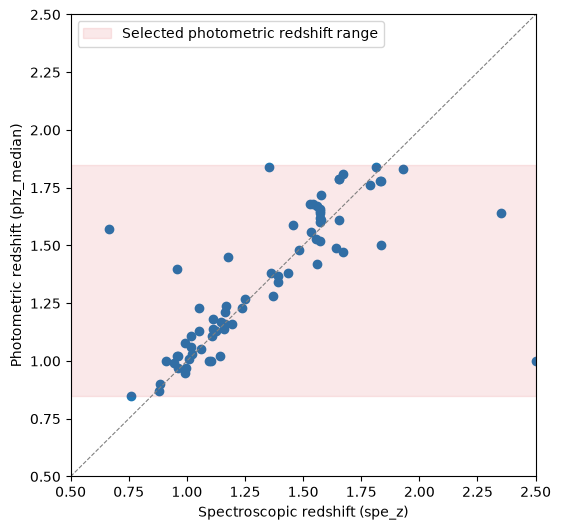

In [12]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(galaxies['spe_z'][reliable], galaxies['phz_median'][reliable], color='tab:blue')
ax.plot([0.5, 2.5], [0.5, 2.5], color='grey', linestyle='--', linewidth=0.8)
ax.axhspan(z_min, z_max, color='tab:red', alpha=0.1, label='Selected photometric redshift range')
ax.set_xlim(0.5, 2.5)
ax.set_ylim(0.5, 2.5)
ax.set_xlabel('Spectroscopic redshift (spe_z)')
ax.set_ylabel('Photometric redshift (phz_median)')
_ = ax.legend(loc='upper left')

In [13]:
spec_z_reliable = np.asarray(galaxies['spe_z'][reliable], dtype=float)
dz = (np.asarray(galaxies['phz_median'][reliable]) - spec_z_reliable) / (1 + spec_z_reliable)
nmad = 1.48 * np.median(np.abs(dz - np.median(dz)))
inside_90 = ((spec_z_reliable >= galaxies['phz_90_int_1'][reliable])
             & (spec_z_reliable <= galaxies['phz_90_int_2'][reliable]))

print(f'NMAD = {nmad:.3f}, outlier fraction = {np.mean(np.abs(dz) > 0.15):.1%}')
print(f'{inside_90.mean():.0%} of the spectroscopic redshifts are within the 90% interval of the photometric redshift')

NMAD = 0.038, outlier fraction = 8.2%
63% of the spectroscopic redshifts are within the 90% interval of the photometric redshift


In [14]:
image_table = Irsa.query_sia(pos=(coords_cutout, 10 * u.arcsec), collection='euclid_dr1_deep_DpdMerBksMosaic', facility='Euclid')

In [15]:
science_images = image_table[image_table['dataproduct_subtype'] == 'science']
science_images['obs_id', 'energy_bandpassname', 'access_url']

obs_id,energy_bandpassname,access_url
object,object,object
101834044_360045416_NISP,Y,https://irsacloud.ipac.caltech.edu/ibe/data/euclid/dr1/MER/101834044/NISP/EUC_MER_BGSUB-MOSAIC-NIR-Y_TILE101834044-AA80BA_20250827T225109.933690Z_00.00.fits
101834044_360045416_NISP,J,https://irsacloud.ipac.caltech.edu/ibe/data/euclid/dr1/MER/101834044/NISP/EUC_MER_BGSUB-MOSAIC-NIR-J_TILE101834044-23A4A4_20250827T225130.868288Z_00.00.fits
101834044_360045416_NISP,H,https://irsacloud.ipac.caltech.edu/ibe/data/euclid/dr1/MER/101834044/NISP/EUC_MER_BGSUB-MOSAIC-NIR-H_TILE101834044-719647_20250827T224849.611941Z_00.00.fits
101834044_360045416_VIS,VIS,https://irsacloud.ipac.caltech.edu/ibe/data/euclid/dr1/MER/101834044/VIS/EUC_MER_BGSUB-MOSAIC-VIS_TILE101834044-F20EA5_20250828T043943.523084Z_00.00.fits


In [16]:
vis_mosaic = science_images[science_images['energy_bandpassname'] == 'VIS'][0]
filename = vis_mosaic['access_url']

In [17]:
cloud_info = json.loads(vis_mosaic['cloud_access'])
s3_path = f"s3://{cloud_info['aws']['bucket_name']}/{cloud_info['aws']['key']}"
s3_path

's3://nasa-irsa-euclid-dr1/dr1/MER/101834044/VIS/EUC_MER_BGSUB-MOSAIC-VIS_TILE101834044-F20EA5_20250828T043943.523084Z_00.00.fits'

In [18]:
# Open the file without downloading it, and read only the cutout
hdu = fits.open(s3_path, fsspec_kwargs={'anon': True})
header = hdu[0].header

cutout_image = Cutout2D(hdu[0].section, position=coords_cutout, size=im_cutout, wcs=WCS(header))
cutout_image.data.shape

(3000, 3000)

In [19]:
brightest = galaxies[reliable]
if len(brightest) == 0:
    raise ValueError('No galaxy has a reliable spectroscopic redshift; try a larger region or a different redshift range.')
brightest.sort(keys='flux_h_unif', reverse=True)

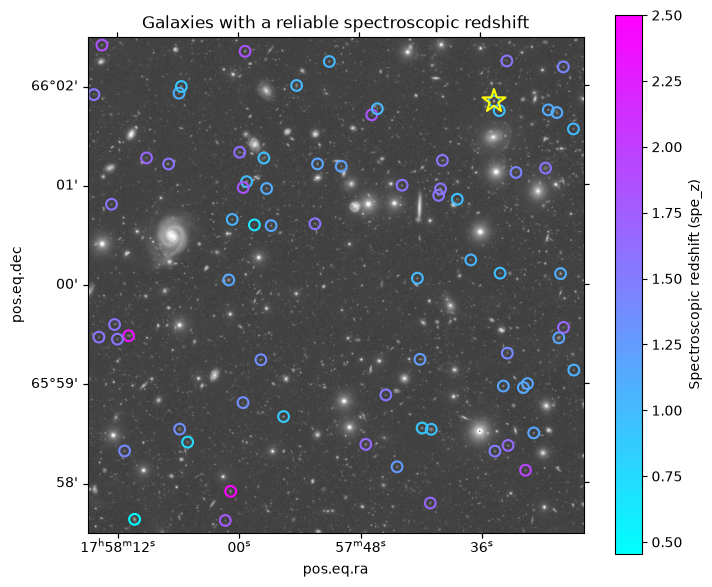

In [20]:
fig = plt.figure(figsize=(8, 7))
ax = plt.subplot(projection=cutout_image.wcs)

ax.imshow(cutout_image.data, cmap='gray', origin='lower',
          norm=ImageNormalize(cutout_image.data, interval=PercentileInterval(99.9), stretch=LogStretch()))
# Open circles, with their edge colored by the spectroscopic redshift
spec_z_values = np.asarray(brightest['spe_z'], dtype=float)
norm = plt.Normalize(spec_z_values.min(), spec_z_values.max())
cmap = plt.get_cmap('cool')
ax.scatter(brightest['ra'], brightest['dec'], s=60, facecolors='none', edgecolors=cmap(norm(spec_z_values)),
           linewidths=1.5, transform=ax.get_transform('world'))
ax.scatter(brightest['ra'][0], brightest['dec'][0], s=300, marker='*', facecolors='none', edgecolors='yellow',
           linewidths=1.5, transform=ax.get_transform('world'))

fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label='Spectroscopic redshift (spe_z)')
ax.set_title('Galaxies with a reliable spectroscopic redshift')
plt.show()

In [21]:
brightest['object_id', 'flux_h_unif', 'phz_median', 'phz_90_int_1', 'phz_90_int_2', 'spe_z', 'spe_z_prob', 'spe_z_rel'][:5]

object_id,flux_h_unif,phz_median,phz_90_int_1,phz_90_int_2,spe_z,spe_z_prob,spe_z_rel
,uJy,,,,,,
int64,float64,float64,float64,float64,float64,float64,float64
2693942861660307299,35.6736145,0.9499999881,0.9399999976,0.9700000286,0.9908273816,0.9940100908,0.4439487755
2694895505660212987,34.81120682,1.399999976,1.379999995,1.429999948,0.9596195221,0.9997035265,0.4284732938
2693730958660194422,34.32209396,1.610000014,1.580000043,1.649999976,1.576032281,0.9988761544,0.1739021391
2694759174660334767,30.42105865,1.029999971,1,1.059999943,1.020510793,0.9999924898,0.6789525151
2693671071660017095,28.08583832,1,0.9599999785,1.00999999,1.105705023,0.9999451041,0.379014641


In [22]:
SPECTRUMDM_URL = 'https://irsacloud.ipac.caltech.edu/api/spectrumdm/convert/'
SPECTRUM_DATASET_ID = 'euclid_combspec_dr1'


def spectrum_url(path, hdu):
    """Build the spectrumDM URL of one spectrum.

    Parameters
    ----------
    path : str
        Path of the spectrum file, from the ``path`` column of the association table.
    hdu : int
        Number of the HDU of the spectrum in the file.

    Returns
    -------
    str
        URL that returns the spectrum as a VOTable.
    """
    return f'{SPECTRUMDM_URL}{path}?dataset_id={SPECTRUM_DATASET_ID}&hdu={hdu}'


def find_spectra(object_id):
    """Find the spectra of an object in the spectrum association table.

    Parameters
    ----------
    object_id : int
        MER object ID of the source.

    Returns
    -------
    astropy.table.Table
        One row per spectrum, with the file path and HDU number of the spectrum, and its spectrumDM URL.
    """
    query = f"""
        SELECT objectid, tileid, path, hdu
        FROM euclid.objectid_spectrafile_association_dr1
        WHERE objectid = {object_id}
    """
    spectrum_files = Irsa.query_tap(query).to_table()
    spectrum_files['url'] = [spectrum_url(path, hdu) for path, hdu in zip(spectrum_files['path'], spectrum_files['hdu'])]
    return spectrum_files

In [23]:
for bright_galaxy in brightest:
    result_spectra = find_spectra(bright_galaxy['object_id'])
    if len(result_spectra) > 0:
        break
    print(f"No spectra listed for object {bright_galaxy['object_id']}, trying the next galaxy")
else:
    raise ValueError('None of the galaxies with a reliable spectroscopic redshift has a spectrum listed; '
                     'try a larger region or a different redshift range.')

obj_id = bright_galaxy['object_id']
photo_z = bright_galaxy['phz_median']
spec_z = bright_galaxy['spe_z']
coords_galaxy = SkyCoord(bright_galaxy['ra'], bright_galaxy['dec'], unit='deg')

print(f'Object {obj_id}: photometric redshift {photo_z:.2f}, spectroscopic redshift {spec_z:.3f}')
result_spectra['objectid', 'tileid', 'hdu']

Object 2693942861660307299: photometric redshift 0.95, spectroscopic redshift 0.991


objectid,tileid,hdu
int64,int64,int64
2693942861660307299,101834044,381
2693942861660307299,101834044,1001


In [24]:
spectra = [QTable.read(url) for url in result_spectra['url']]

In [25]:
def bad_flux_bins(spectrum):
    """Find the flux bins of a spectrum that should not be used.

    Parameters
    ----------
    spectrum : astropy.table.QTable
        Spectrum, with a MASK column.

    Returns
    -------
    numpy.ndarray
        Boolean array, True for the flux bins with an odd MASK value or a MASK value of 64 or more.
    """
    mask = spectrum['MASK'].value
    return (mask % 2 == 1) | (mask >= 64)


def grism_name(spectrum):
    """Tell which kind of grism a spectrum comes from.

    Parameters
    ----------
    spectrum : astropy.table.QTable
        Spectrum, with a WAVELENGTH column.

    Returns
    -------
    str
        ``'Blue grism'`` if the spectrum starts below 1.1 micron, ``'Red grism'`` otherwise.
    """
    return 'Blue grism' if spectrum['WAVELENGTH'].min() < 1.1 * u.micron else 'Red grism'


def best_spectra(spectra):
    """Pick the spectrum with the most usable flux bins for each kind of grism.

    Parameters
    ----------
    spectra : list of astropy.table.QTable
        Spectra of one object.

    Returns
    -------
    dict
        Best spectrum of each kind of grism, keyed by the name of the grism.
    """
    best = {}
    for spectrum in sorted(spectra, key=lambda spectrum: np.sum(~bad_flux_bins(spectrum)), reverse=True):
        best.setdefault(grism_name(spectrum), spectrum)
    return best


best = best_spectra(spectra)
list(best)

['Red grism', 'Blue grism']

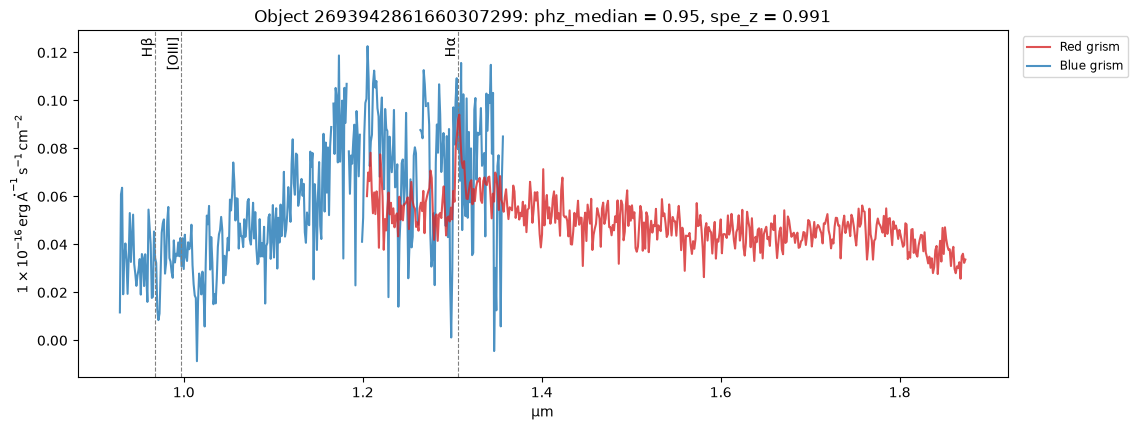

In [26]:
emission_lines = {'Hβ': 4862.7 * u.AA, '[OIII]': 5008.2 * u.AA, 'Hα': 6564.6 * u.AA}
grism_colors = {'Red grism': 'tab:red', 'Blue grism': 'tab:blue'}

fig, ax = plt.subplots(figsize=(12, 4.5))
for name, spectrum in best.items():
    bad = bad_flux_bins(spectrum)
    # Draw the red grism spectrum on top, as it is less noisy where the two grisms overlap
    ax.plot(spectrum['WAVELENGTH'].to(u.micron), np.ma.masked_where(bad, spectrum['SIGNAL']),
            color=grism_colors[name], alpha=0.8, label=name, zorder=3 if name == 'Red grism' else 2)

usable_wavelengths = [spectrum['WAVELENGTH'][~bad_flux_bins(spectrum)] for spectrum in best.values()]
wave_min = min(wavelengths.min() for wavelengths in usable_wavelengths)
wave_max = max(wavelengths.max() for wavelengths in usable_wavelengths)
for line, rest_wavelength in emission_lines.items():
    observed = (rest_wavelength * (1 + spec_z)).to(u.micron)
    if wave_min < observed < wave_max:
        ax.axvline(observed, color='grey', linestyle='--', linewidth=0.8)
        ax.text(observed.value, 0.98, f' {line}', transform=ax.get_xaxis_transform(), rotation=90, va='top', ha='right')

ax.set_title(f'Object {obj_id}: phz_median = {photo_z:.2f}, spe_z = {spec_z:.3f}')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize='small')
plt.show()

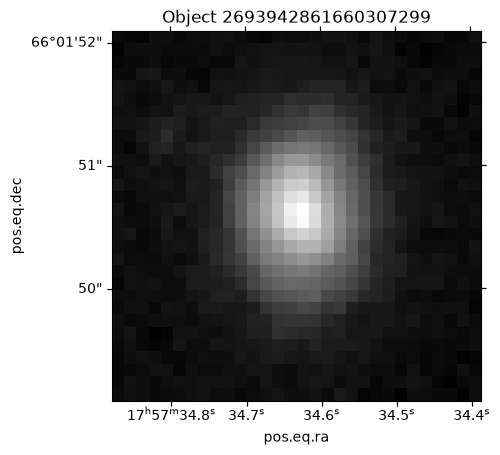

In [27]:
size_galaxy_cutout = 3 * u.arcsec

cutout_galaxy = Cutout2D(hdu[0].section, position=coords_galaxy, size=size_galaxy_cutout, wcs=WCS(header))

ax = plt.subplot(projection=cutout_galaxy.wcs)
ax.imshow(cutout_galaxy.data, cmap='gray', origin='lower',
          norm=ImageNormalize(cutout_galaxy.data, interval=PercentileInterval(99.9), stretch=AsinhStretch()))
_ = ax.set_title(f'Object {obj_id}')

In [28]:
fc = FireflyClient.make_client('https://irsa.ipac.caltech.edu/irsaviewer')


In [29]:
fc.show_fits_image(filename)

{'success': True}

In [30]:
tbl_stream = io.BytesIO()
galaxies.write(tbl_stream, format='votable')

fc.show_table(tbl_stream)

{'success': True}